In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_datareader as data

plt.style.use('fivethirtyeight')
%matplotlib inline

In [2]:
import yfinance as yf
import datetime as dt

stock = "AAPL"
start = dt.datetime(2000, 1, 1)
end = dt.datetime(2026, 11, 1)

df = yf.download(stock, start, end)

[*********************100%***********************]  1 of 1 completed


In [3]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2000-01-03,0.837002,0.841208,0.760359,0.784193,535796800
2000-01-04,0.766435,0.827188,0.756620,0.809430,512377600
2000-01-05,0.777650,0.826721,0.770173,0.775781,778321600
2000-01-06,0.710353,0.800083,0.710353,0.793540,767972800
2000-01-07,0.744002,0.755218,0.714093,0.721570,460734400


In [4]:
df.shape

(6748, 5)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6748 entries, 2000-01-03 to 2026-10-30
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   6748 non-null   float64
 1   (High, AAPL)    6748 non-null   float64
 2   (Low, AAPL)     6748 non-null   float64
 3   (Open, AAPL)    6748 non-null   float64
 4   (Volume, AAPL)  6748 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 316.3 KB


In [6]:
df.isnull().sum()

Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64

In [7]:
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
count,6748.000000,6748.000000,6748.000000,6748.000000,6.748000e+03
mean,55.900306,56.461032,55.286900,55.850977,3.631731e+08
std,80.631693,81.424713,79.754184,80.540043,3.799477e+08
min,0.196207,0.197254,0.190225,0.194263,1.791060e+07
25%,2.250999,2.277170,2.221687,2.246886,9.891010e+07
50%,16.680265,16.824344,16.504323,16.698851,2.396548e+08
75%,68.452530,69.068130,67.238286,68.034007,4.872406e+08
max,348.910004,351.730011,347.299988,349.119995,7.421641e+09


In [8]:
df = df.reset_index()

In [9]:
df.columns

MultiIndex([(  'Date',     ''),
            ( 'Close', 'AAPL'),
            (  'High', 'AAPL'),
            (   'Low', 'AAPL'),
            (  'Open', 'AAPL'),
            ('Volume', 'AAPL')],
           names=['Price', 'Ticker'])

In [10]:
df.to_csv("AAPL.csv")

In [11]:
data01 = pd.read_csv("AAPL.csv")

In [12]:
data01.head()

,Price,Date,Close,High,Low,Open,Volume
0,Ticker,NaN,AAPL,AAPL,AAPL,AAPL,AAPL
1,0,2000-01-03,0.8370022773742676,0.8412080907050877,0.7603587470978729,0.7841931535401442,535796800
2,1,2000-01-04,0.7664346694946289,0.8271880515858712,0.7566203720992737,0.8094295004513068,512377600
3,2,2000-01-05,0.7776501178741455,0.8267208111194863,0.7701731871069165,0.7757808727030664,778321600
4,3,2000-01-06,0.7103534936904907,0.8000825462617555,0.7103534936904907,0.7935402136211008,767972800


In [13]:
# Candlesticks 
import plotly.graph_objects as go

fig = go.Figure(data=[go.Candlestick(x = data01['Date'], open = data01['Open'], 
                                    high = data01['High'],
                                    low = data01['Low'], 
                                    close = data01['Close'])])
fig.update_layout(xaxis_rangeslider_visible=False)
fig.show()

In [14]:
df = df.drop(['Date'], axis = 1)

C:\Users\Kumar Vaibhav\AppData\Local\Temp\ipykernel_7032\1002300862.py:1: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  df = df.drop(['Date'], axis = 1)


In [15]:
df.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
0,0.837002,0.841208,0.760359,0.784193,535796800
1,0.766435,0.827188,0.756620,0.809430,512377600
2,0.777650,0.826721,0.770173,0.775781,778321600
3,0.710353,0.800083,0.710353,0.793540,767972800
4,0.744002,0.755218,0.714093,0.721570,460734400


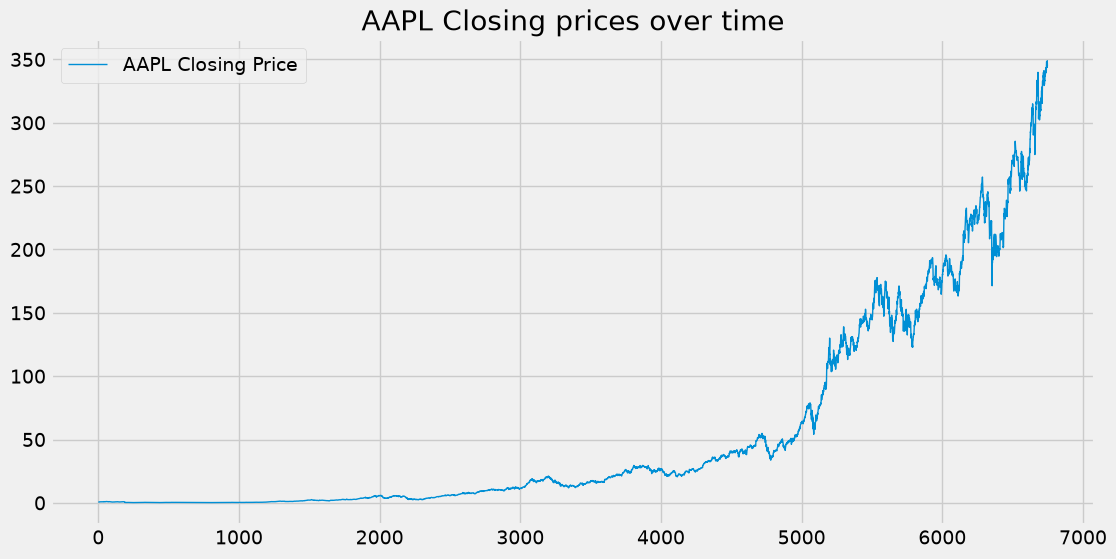

In [16]:
plt.figure(figsize=(12, 6))
plt.plot(df['Close'], label = f'{stock} Closing Price', linewidth = 1)
plt.title(f'{stock} Closing prices over time')
plt.legend()
plt.show()

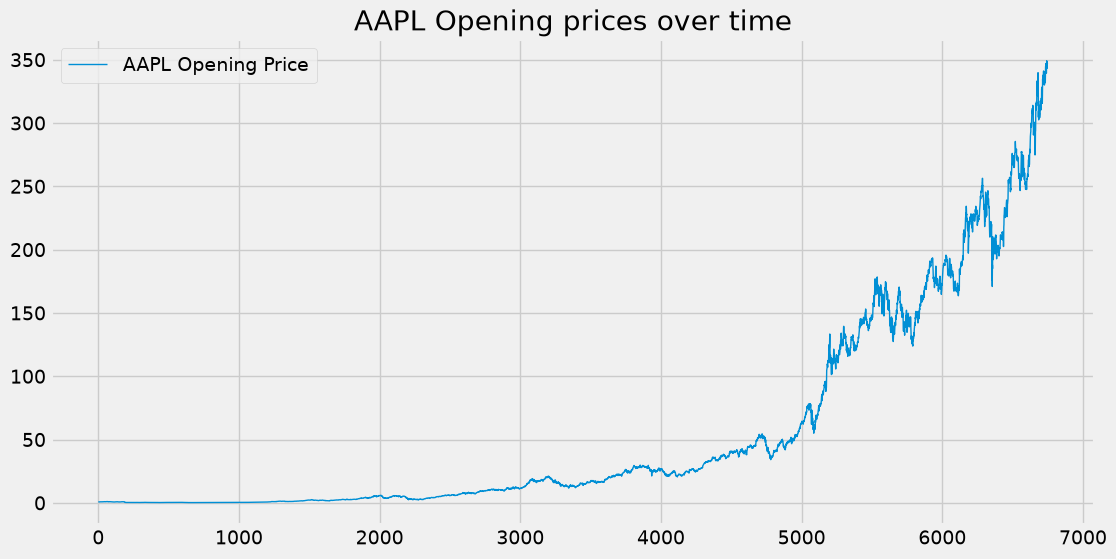

In [17]:
plt.figure(figsize=(12, 6))
plt.plot(df['Open'], label = f'{stock} Opening Price', linewidth = 1)
plt.title(f'{stock} Opening prices over time')
plt.legend()
plt.show()

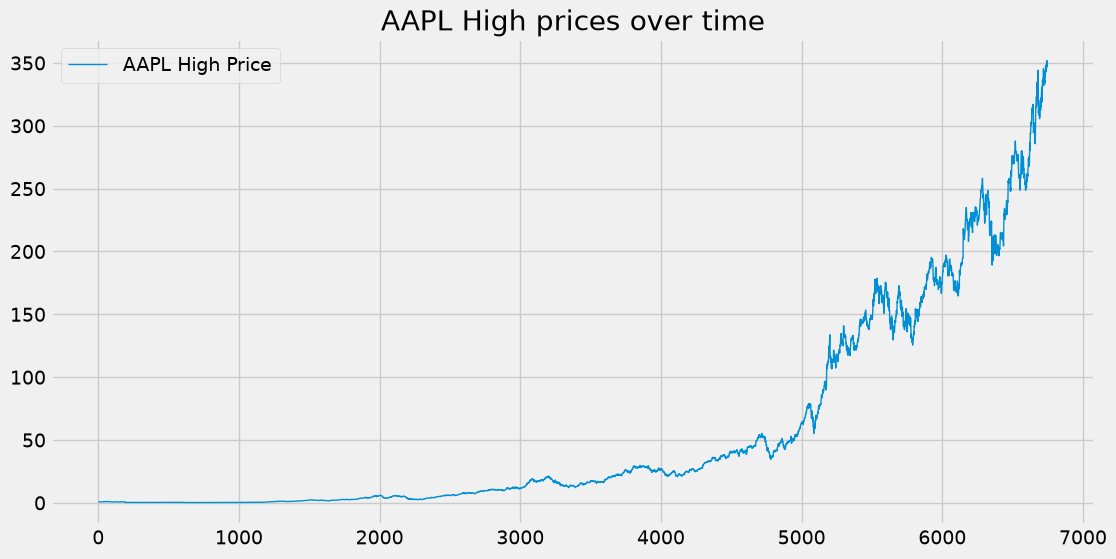

In [18]:
plt.figure(figsize=(12, 6))
plt.plot(df['High'], label = f'{stock} High Price', linewidth = 1)
plt.title(f'{stock} High prices over time')
plt.legend()
plt.show()

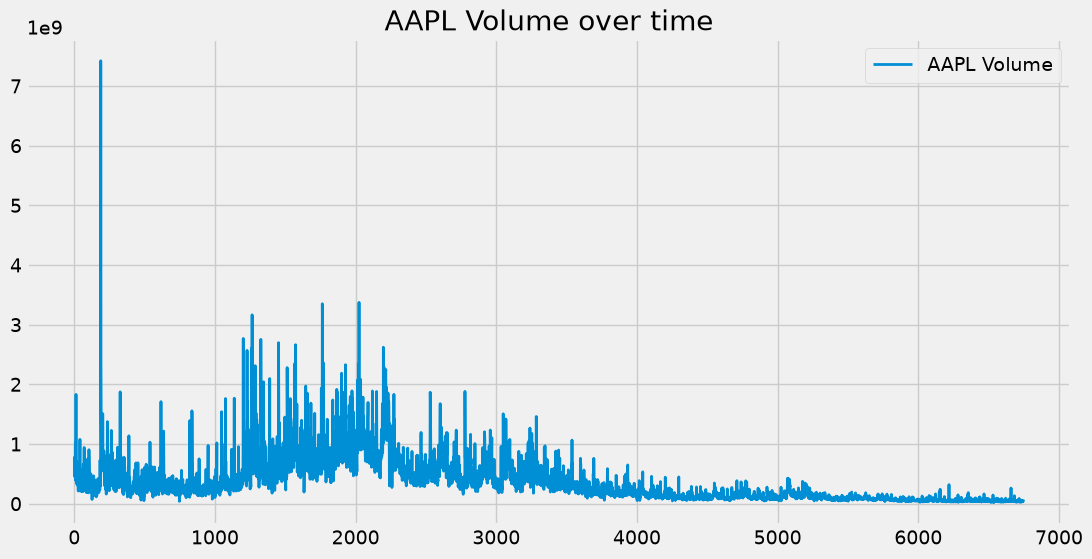

In [19]:
plt.figure(figsize=(12, 6))
plt.plot(df['Volume'], label = f'{stock} Volume', linewidth = 2)
plt.title(f'{stock} Volume over time')
plt.legend()
plt.show()

In [20]:
# Moving Average
# [10, 20, 30, 40, 50, 60, 70, 80, 90]
# moving average for last 5 days -> null null null null 30.0 40.0 50.0

temp_data = [10, 20, 30, 40, 50, 60, 70, 80, 90]
print(sum(temp_data[2:7])/5)

50.0


In [21]:
import pandas as pd
df01 = pd.DataFrame(temp_data)

In [22]:
df01.rolling(5).mean()

,0
0,NaN
1,NaN
2,NaN
3,NaN
4,30.0
5,40.0
6,50.0
7,60.0
8,70.0


In [23]:
ma100 = df.Close.rolling(100).mean()

In [24]:
ma100

Ticker,AAPL
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
6743,319.588541
6744,319.949922
6745,320.317471
6746,320.793769


In [25]:
ma200 = df.Close.rolling(200).mean()

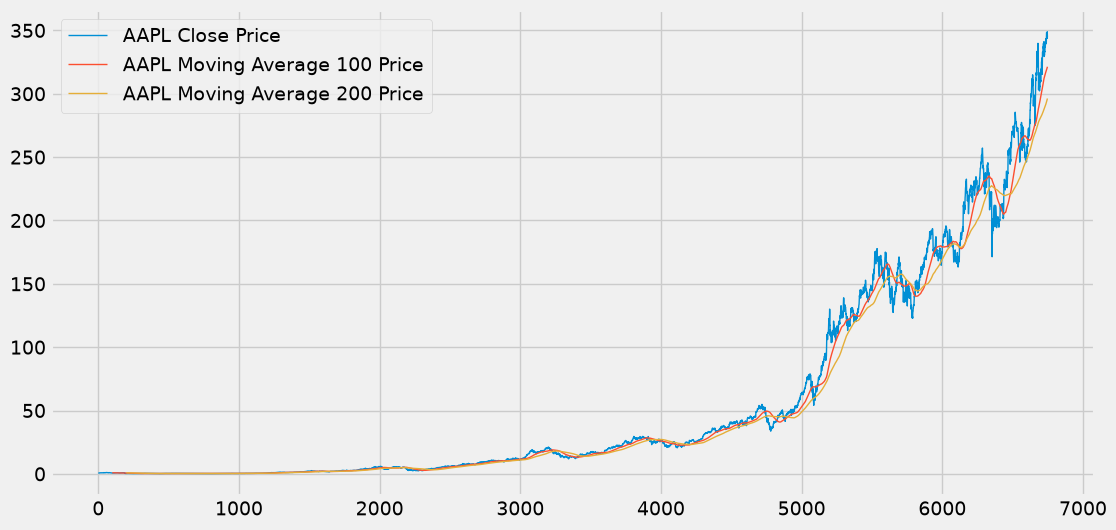

In [26]:
plt.figure(figsize=(12, 6))
plt.plot(df.Close, label = f'{stock} Close Price', linewidth = 1)
plt.plot(ma100, label = f'{stock} Moving Average 100 Price', linewidth = 1)
plt.plot(ma200, label = f'{stock} Moving Average 200 Price', linewidth = 1)
plt.legend()
plt.show()

In [27]:
ema100 = df.Close.ewm(span=100, adjust = False).mean()

In [28]:
ema200 = df['Close'].ewm(span=200, adjust = False).mean()

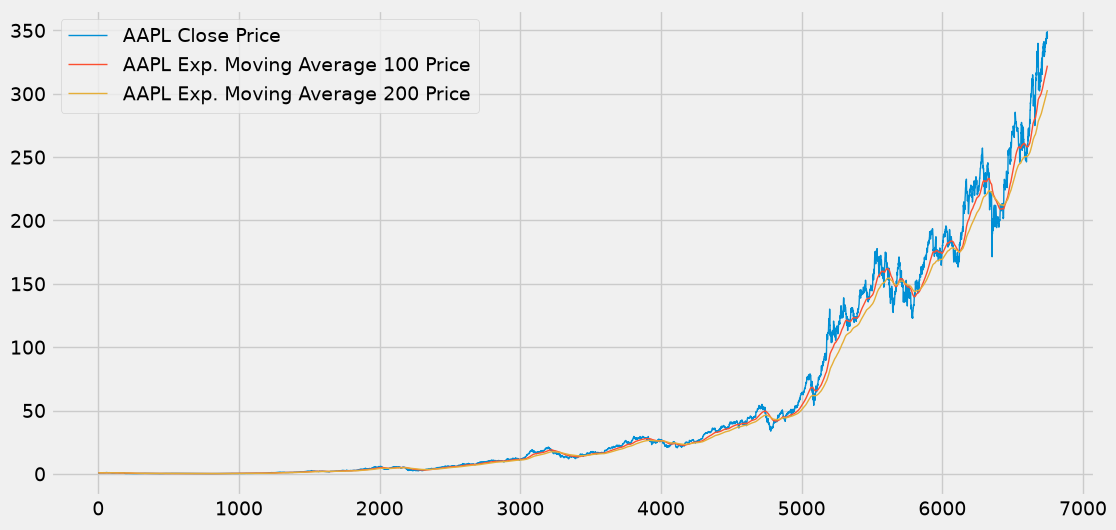

In [29]:
plt.figure(figsize=(12, 6))
plt.plot(df.Close, label = f'{stock} Close Price', linewidth = 1)
plt.plot(ema100, label = f'{stock} Exp. Moving Average 100 Price', linewidth = 1)
plt.plot(ema200, label = f'{stock} Exp. Moving Average 200 Price', linewidth = 1)
plt.legend()
plt.show()

In [30]:
# Training & Testing

data_training = pd.DataFrame(df['Close'][0:int(len(df)*0.70)])
data_testing = pd.DataFrame(df['Close'][int(len(df)*0.70): int(len(df))])

In [31]:
data_training.shape

(4723, 1)

In [32]:
data_testing.shape

(2025, 1)

In [33]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range = (0, 1))

In [34]:
data_training_array = scaler.fit_transform(data_training)

In [35]:
data_training_array

array([[0.01173024],
       [0.01043845],
       [0.01064375],
       ...,
       [0.96635524],
       [0.96410648],
       [0.97751241]], shape=(4723, 1))

In [36]:
data_training_array.shape[0]

4723

In [37]:
x_train = []
y_train = []

for i in range(100, data_training_array.shape[0]):
    x_train.append(data_training_array[i-100:i])
    y_train.append(data_training_array[i, 0])

x_train, y_train  = np.array(x_train), np.array(y_train)

In [38]:
x_train.shape

(4623, 100, 1)

In [39]:
# Model Building
from keras.layers import Dense, Dropout, LSTM
from keras.models import Sequential

LSTM Input -> 3D Array (batch_size, time_steps, seq_len)
LSTM 2D OR 3D
2D -> (batch_sizem units)
3D -> (batch_size, time_steps, units)

In [40]:
model = Sequential()

model.add(LSTM(units = 50, activation = 'relu', return_sequences = True, input_shape = (x_train.shape[1],1)))
model.add(Dropout(0.2))

model.add(LSTM(units = 60, activation = 'relu', return_sequences = True))
model.add(Dropout(0.3))

model.add(LSTM(units = 80, activation = 'relu', return_sequences = True))
model.add(Dropout(0.4))

model.add(LSTM(units = 120, activation = 'relu'))
model.add(Dropout(0.5))

model.add(Dense(units = 1))

c:\Users\Kumar Vaibhav\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [41]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 60)        │        26,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 60)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 100, 80)        │        45,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100, 80)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 120)            │        96,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,761 (698.29 KB)

 Trainable params: 178,761 (698.29 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
model.compile(optimizer = 'adam', loss = 'mean_squared_error')
model.fit(x_train, y_train, epochs = 50)

Epoch 1/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 56s 338ms/step - loss: 0.0104
Epoch 2/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 126s 645ms/step - loss: 0.0028
Epoch 3/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 71s 486ms/step - loss: 0.0025
Epoch 4/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 74s 510ms/step - loss: 0.0029
Epoch 5/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 109s 755ms/step - loss: 0.0026
Epoch 6/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 48s 330ms/step - loss: 0.0022
Epoch 7/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 57s 162ms/step - loss: 0.0021
Epoch 8/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 22s 152ms/step - loss: 0.0020
Epoch 9/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 159ms/step - loss: 0.0020
Epoch 10/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 25s 173ms/step - loss: 0.0019
Epoch 11/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 27s 186ms/step - loss: 0.0021
Epoch 12/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 26s 180ms/step - loss: 0.0018
Epoch 13/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 160ms/step - loss: 0.0019
Epoch 14/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 24s 162ms/step - loss: 0.0017
Epoch 15/50
1

In [43]:
past_100_days = data_training.tail(100)

In [44]:
import pandas as pd

final_df = pd.concat([past_100_days, data_testing], ignore_index=True)

In [45]:
final_df.head()

Ticker,AAPL
0,43.859737
1,44.170479
2,44.059830
3,44.342335
4,44.292889


In [46]:
input_data = scaler.fit_transform(final_df)

In [47]:
x_test = []
y_test = []

for i in range(100, input_data.shape[0]):
    x_test.append(input_data[i-100:i])
    y_test.append(input_data[i, 0])

x_test, y_test  = np.array(x_test), np.array(y_test)

In [48]:
x_test.shape

(2025, 100, 1)

In [49]:
y_predicted = model.predict(x_test)

64/64 ━━━━━━━━━━━━━━━━━━━━ 27s 382ms/step


In [50]:
y_predicted.shape

(2025, 1)

In [51]:
scaler.scale_

array([0.00317257])

In [52]:
scaler_factor = 1 / 0.0035166
y_predicted = y_predicted * scaler_factor
y_test = y_test * scaler_factor

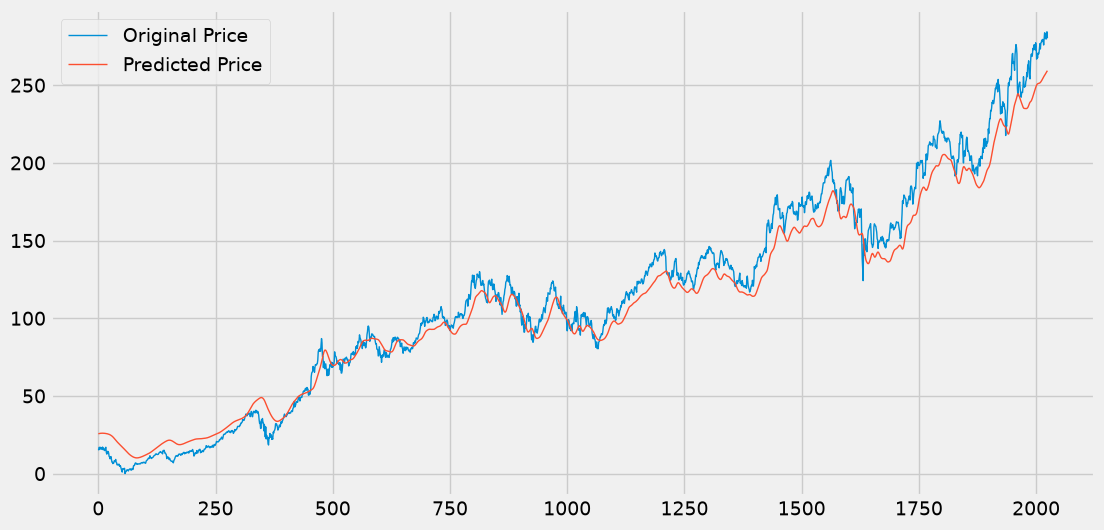

In [53]:
plt.figure(figsize=(12, 6))
plt.plot(y_test, label = 'Original Price', linewidth = 1)
plt.plot(y_predicted, label = 'Predicted Price', linewidth = 1)
plt.legend()
plt.show()

In [54]:
model.save('stock_dl_model.h5')